# Remaining onboarding checks — Earth-centric control and a clean Jupiter null (Oct 8, 2026)

Two control experiments from the onboarding notebook, each validated several ways and checked against physical expectations.

* **A. Earth-centric control.** Re-express the observer's position as Earth + LEO offset (`S = E + δ`): replace `n·S` by
  `n·δ` (`n·E` is already a feature). Same information, different coordinates. **Prediction: a null** — the LEO
  offset (≈7000 km ≈ 4.7×10⁻⁵ AU) changes the zodiacal brightness by ~10⁻⁴, an MSE term ~10⁵× below the current error.
* **B. A clean Jupiter null.** Kelsall (1998) contains no Jupiter, yet on 10/07 removing `n·J` hurt extrapolation — the
  only thing `n·J` adds beyond the fixed sky frame is Jupiter's 12° drift over the mission, i.e. a slow *clock*. A clean
  null compares Jupiter against **time-matched controls**: fake planets with exactly Jupiter's motion seen from other
  directions (rotated 45° and 90° about the ecliptic pole), and Jupiter with its timing scrambled.
  **Predictions:** if `n·J` is only a clock, fake planets ≈ Jupiter, scrambled ≈ no Jupiter; on an *interpolation* split
  (no clock needed) all variants ≈ equal.

**Protocol.** 64-64-32-16 MLP, one-cycle LR (peak 1e-3), 100 epochs. *Chronological:* fit days 0–100, validate
100–111.4, test 111.4–139.7, 5 seeds. *Interpolation:* 30-day alternating blocks, 3 seeds. Runs were done in `sweeps/`
(`configs_v6.jl`); this notebook loads the saved results and runs top-to-bottom in a few minutes.

### Summary
| check | prediction | result |
|---|---|---|
| **A. Earth-centric** (`n·S → n·δ`) | null (parallax ~10⁻⁴) | **Null confirmed** on 3 tests: chrono ensemble MSE 2.70e-4 vs 2.67e-4, block 1.08e-5 vs 1.05e-5, linear/quadratic fits *identical*. But `n·δ` inherits the Earth-avoidance pointing rule → all-sky domain shrinks **32% → 5%**. |
| **B. Jupiter vs time-matched controls** | fake planets ≈ Jupiter; scrambled ≈ none; interpolation: no benefit | **Confirmed on robust metrics**: ensembles with time information 1.3–1.6% median error vs 2.6% without (scrambled 2.59% ≈ none 2.61%); on interpolation the benefit disappears (0.13–0.17%, time-free slightly better). Test MSE itself is too seed-noisy to rank them. |

**Bottom line:** in this data `n·J` helps only by carrying *time* (Jupiter's 12° drift), not Jupiter physics — Kelsall has no
Jupiter component. A fake planet moving the same way helps just as much; Jupiter with scrambled timing doesn't help at all.


In [1]:
include(joinpath(@__DIR__, "zodi_setup.jl"))
for f in ("mb_train.jl", "extra_features.jl", "nb_verify_fns.jl", "summary_helpers.jl", "checks_helpers.jl")
    include(joinpath(@__DIR__, "sweeps", f))
end
println("\nfeature sets used today:")
for k in (:look_dir, :earth_centric, :look_dir_Jrot45, :look_dir_Jrot90, :look_dir_Jscr, :look_dir_noJ)
    println("  ", rpad(k, 17), join(FEATURE_SETS[k], ", "))
end


  Activating project at `c:\JuliaProjects\More_zodi`


description: Zodiacal light predictions for SPHEREx pointing directions
wavelength:  5.0 micron
units:       MJy/sr
N = 423607 exposures;  emission range = (0.31956938511238003, 1.0941130974339088)
n·n     median  1.000e+00   iqr  0.000e+00
n·S     median  4.851e-03   iqr  3.475e-01
n·z     median  9.747e-03   iqr  1.361e+00
n·E     median  4.805e-03   iqr  3.475e-01
n·vS    median  1.615e-02   iqr  1.356e+00
n·vE    median  3.680e-02   iqr  1.383e+00
n·J     median -5.953e-02   iqr  2.659e+00
n·x     median  5.145e-02   iqr  8.549e-01
n·y     median -1.072e-03   iqr  5.523e-01
S·S     median  1.037e+00   iqr  1.341e-02
S·z     median  2.050e-04   iqr  6.195e-05
S·E     median  1.037e+00   iqr  1.341e-02
S·vS    median -1.048e-02   iqr  5.980e-02
S·vE    median -5.250e-03   iqr  2.289e-02
S·J     median -4.519e+00   iqr  1.400e+00
S·x     median  2.056e-01   iqr  1.095e+00
S·y     median -8.518e-01   iqr  3.210e-01
z·z     median  1.000e+00   iqr  0.000e+00
z·E     median  2.096e-04   

## A. Earth-centric control

### A1. Pre-flight physics: what is `δ`, and how big should its effect be?


In [2]:
dn = vec(sqrt.(sum(δ_vec .^ 2, dims=1)))
tr80, te80 = splits["80/20 Chronological"]
nd = Fd_raw[:, findfirst(==("n·δ"), dot_names_all)]
@printf("|δ| = %.2e – %.2e AU = %.0f – %.0f km  (Earth radius 6371 km + ~650–675 km altitude ✓)\n", extrema(dn)..., (extrema(dn) .* 1.496e8)...)
@printf("n·S vs n·E: correlation %.6f, max |difference| %.1e AU — n·S already ≈ n·E\n",
        cor(Fd_raw[:, findfirst(==("n·S"), dot_names_all)], Fd_raw[:, findfirst(==("n·E"), dot_names_all)]), maximum(abs.(nd)))
@printf("n·δ / |δ| in training spans %.2f – %.2f: the boresight is always ≥%.0f° from Earth's centre (Earth avoidance)\n",
        extrema(nd[tr80] ./ dn[tr80])..., acosd(-minimum(nd[tr80] ./ dn[tr80])))
println("→ because |δ| is nearly constant, n·δ ≈ |δ|·n·δ̂ (corr ", round(cor(nd, Fd_raw[:, findfirst(==("n·δ̂"), dot_names_all)]), digits=4),
        "): it mostly encodes the POINTING RULE, and only ~1e-4 of real parallax physics")
P = parallax_check(load_prefix("final_base_s"))
@printf("\nTrained baseline ensemble: moving the observer from SPHEREx to Earth's centre changes predictions by\nmedian %.1e, 99th percentile %.1e (fractional). Physics estimate |δ|·|dlnI/dlnr| ≈ %.0e.\n",
        P.median_frac, P.p99_frac, P.physics_estimate)


|δ| = 4.69e-05 – 4.71e-05 AU = 7014 – 7046 km  (Earth radius 6371 km + ~650–675 km altitude ✓)
n·S vs n·E: correlation 1.000000, max |difference| 4.7e-05 AU — n·S already ≈ n·E
n·δ / |δ| in training spans 0.76 – 1.00: the boresight is always ≥139° from Earth's centre (Earth avoidance)
→ because |δ| is nearly constant, n·δ ≈ |δ|·n·δ̂ (corr 0.9998): it mostly encodes the POINTING RULE, and only ~1e-4 of real parallax physics

Trained baseline ensemble: moving the observer from SPHEREx to Earth's centre changes predictions by
median 2.8e-05, 99th percentile 1.3e-04 (fractional). Physics estimate |δ|·|dlnI/dlnr| ≈ 9e-05.


### A2. Does the Earth-centric switch change accuracy? (chronological and interpolation splits)


In [3]:
display(compare_table(A_CHRONO))
display(compare_table(A_BLOCK))


Row,variant,seeds,val_ens,test_seed_median,test_seed_range,test_ens,test_ens_median_frac_pct,late_test_bias
,String,Int64,String,String,String,String,Float64,String
1,"baseline {n·S, n·E, …}",5,3.09e-05,4.46e-04,3.28e-04 – 5.59e-04,2.67e-04,1.438,-0.0144
2,"Earth-centric {n·E, n·δ, …}",5,3.07e-05,3.97e-04,3.30e-04 – 4.65e-04,2.70e-04,1.126,-0.0129


Row,variant,seeds,val_ens,test_seed_median,test_seed_range,test_ens,test_ens_median_frac_pct,late_test_bias
,String,Int64,String,String,String,String,Float64,String
1,"baseline {n·S, n·E, …}",3,—,1.36e-05,1.27e-05 – 1.57e-05,1.05e-05,0.167,—
2,"Earth-centric {n·E, n·δ, …}",3,—,1.38e-05,1.29e-05 – 1.79e-05,1.08e-05,0.171,—


### A3. Linear models: is the `n·δ` coefficient ≈ 0? (onboarding's suggested check)


In [4]:
for fs in (:look_dir, :earth_centric)
    L = linear_coefs(FEATURE_SETS[fs])
    @printf("%-14s  linear test MSE %.3e | linear+quadratic test MSE %.3e\n", fs, L.mse_lin, L.mse_quad)
    display(L.table)
end


Row,feature,coefficient_MJy_sr_per_sigma
,String,Float64
1,n·S,1110.0
2,n·z,-0.0313
3,n·E,-1110.0
4,n·vS,0.0398
5,n·vE,0.15
6,n·J,-0.932
7,n·x,-0.142
8,n·y,0.914


look_dir        linear test MSE 2.460e-02 | linear+quadratic test MSE 4.063e-03
earth_centric   linear test MSE 2.460e-02 | linear+quadratic test MSE 4.063e-03


Row,feature,coefficient_MJy_sr_per_sigma
,String,Float64
1,n·δ,0.0132
2,n·z,-0.0313
3,n·E,-0.0303
4,n·vS,0.0398
5,n·vE,0.15
6,n·J,-0.932
7,n·x,-0.142
8,n·y,0.914


### A4. Does the trained network actually use `n·δ`? — permutation importance
Shuffle one feature across the held-out exposures and measure the ensemble's MSE ratio (1.00 = feature unused).


In [5]:
ec_chrono = load_prefix("v_ec_s")
println("Earth-centric ensemble, chronological TEST period:"); display(perm_importance(ec_chrono, ec_chrono[1].te_idx))
ec_blk = load_prefix("blk_ec_s")
println("Earth-centric ensemble, 30-day-block TEST blocks:"); display(perm_importance(ec_blk, ec_blk[1].te_idx))


Row,feature,mse_ratio_when_shuffled
,String,Float64
1,n·y,1.11666e5
2,n·J,85839.9
3,n·E,145.531
4,n·z,69.173
5,n·vE,41.426
6,n·x,8.969
7,n·vS,7.228
8,n·δ,1.122


Earth-centric ensemble, chronological TEST period:
Earth-centric ensemble, 30-day-block TEST blocks:


Row,feature,mse_ratio_when_shuffled
,String,Float64
1,n·y,135756.0
2,n·J,62363.0
3,n·E,2699.25
4,n·z,1114.46
5,n·x,970.803
6,n·vE,870.606
7,n·vS,579.229
8,n·δ,3.821


### A5. All-sky consequence: `n·δ` inherits the Earth-avoidance pointing rule


Row,model,region,sky_pct,rms_MJy_sr,median_abs_frac_pct,median_ensemble_std,negative_predictions
,String,String,Float64,Float64,Float64,Float64,Int64
1,baseline,in-domain,32.283,0.0110178,0.744899,0.00450608,0
2,baseline,out-of-domain,67.717,79.6733,5.19193,0.112376,0
3,baseline,whole sky,100.0,65.5634,2.8695,0.0256892,0
4,Earth-centric,in-domain,5.27941,0.00245725,0.191219,0.00183511,0
5,Earth-centric,out-of-domain,94.7206,67.3112,48.792,0.360607,0
6,Earth-centric,whole sky,100.0,65.5103,44.3065,0.339453,0


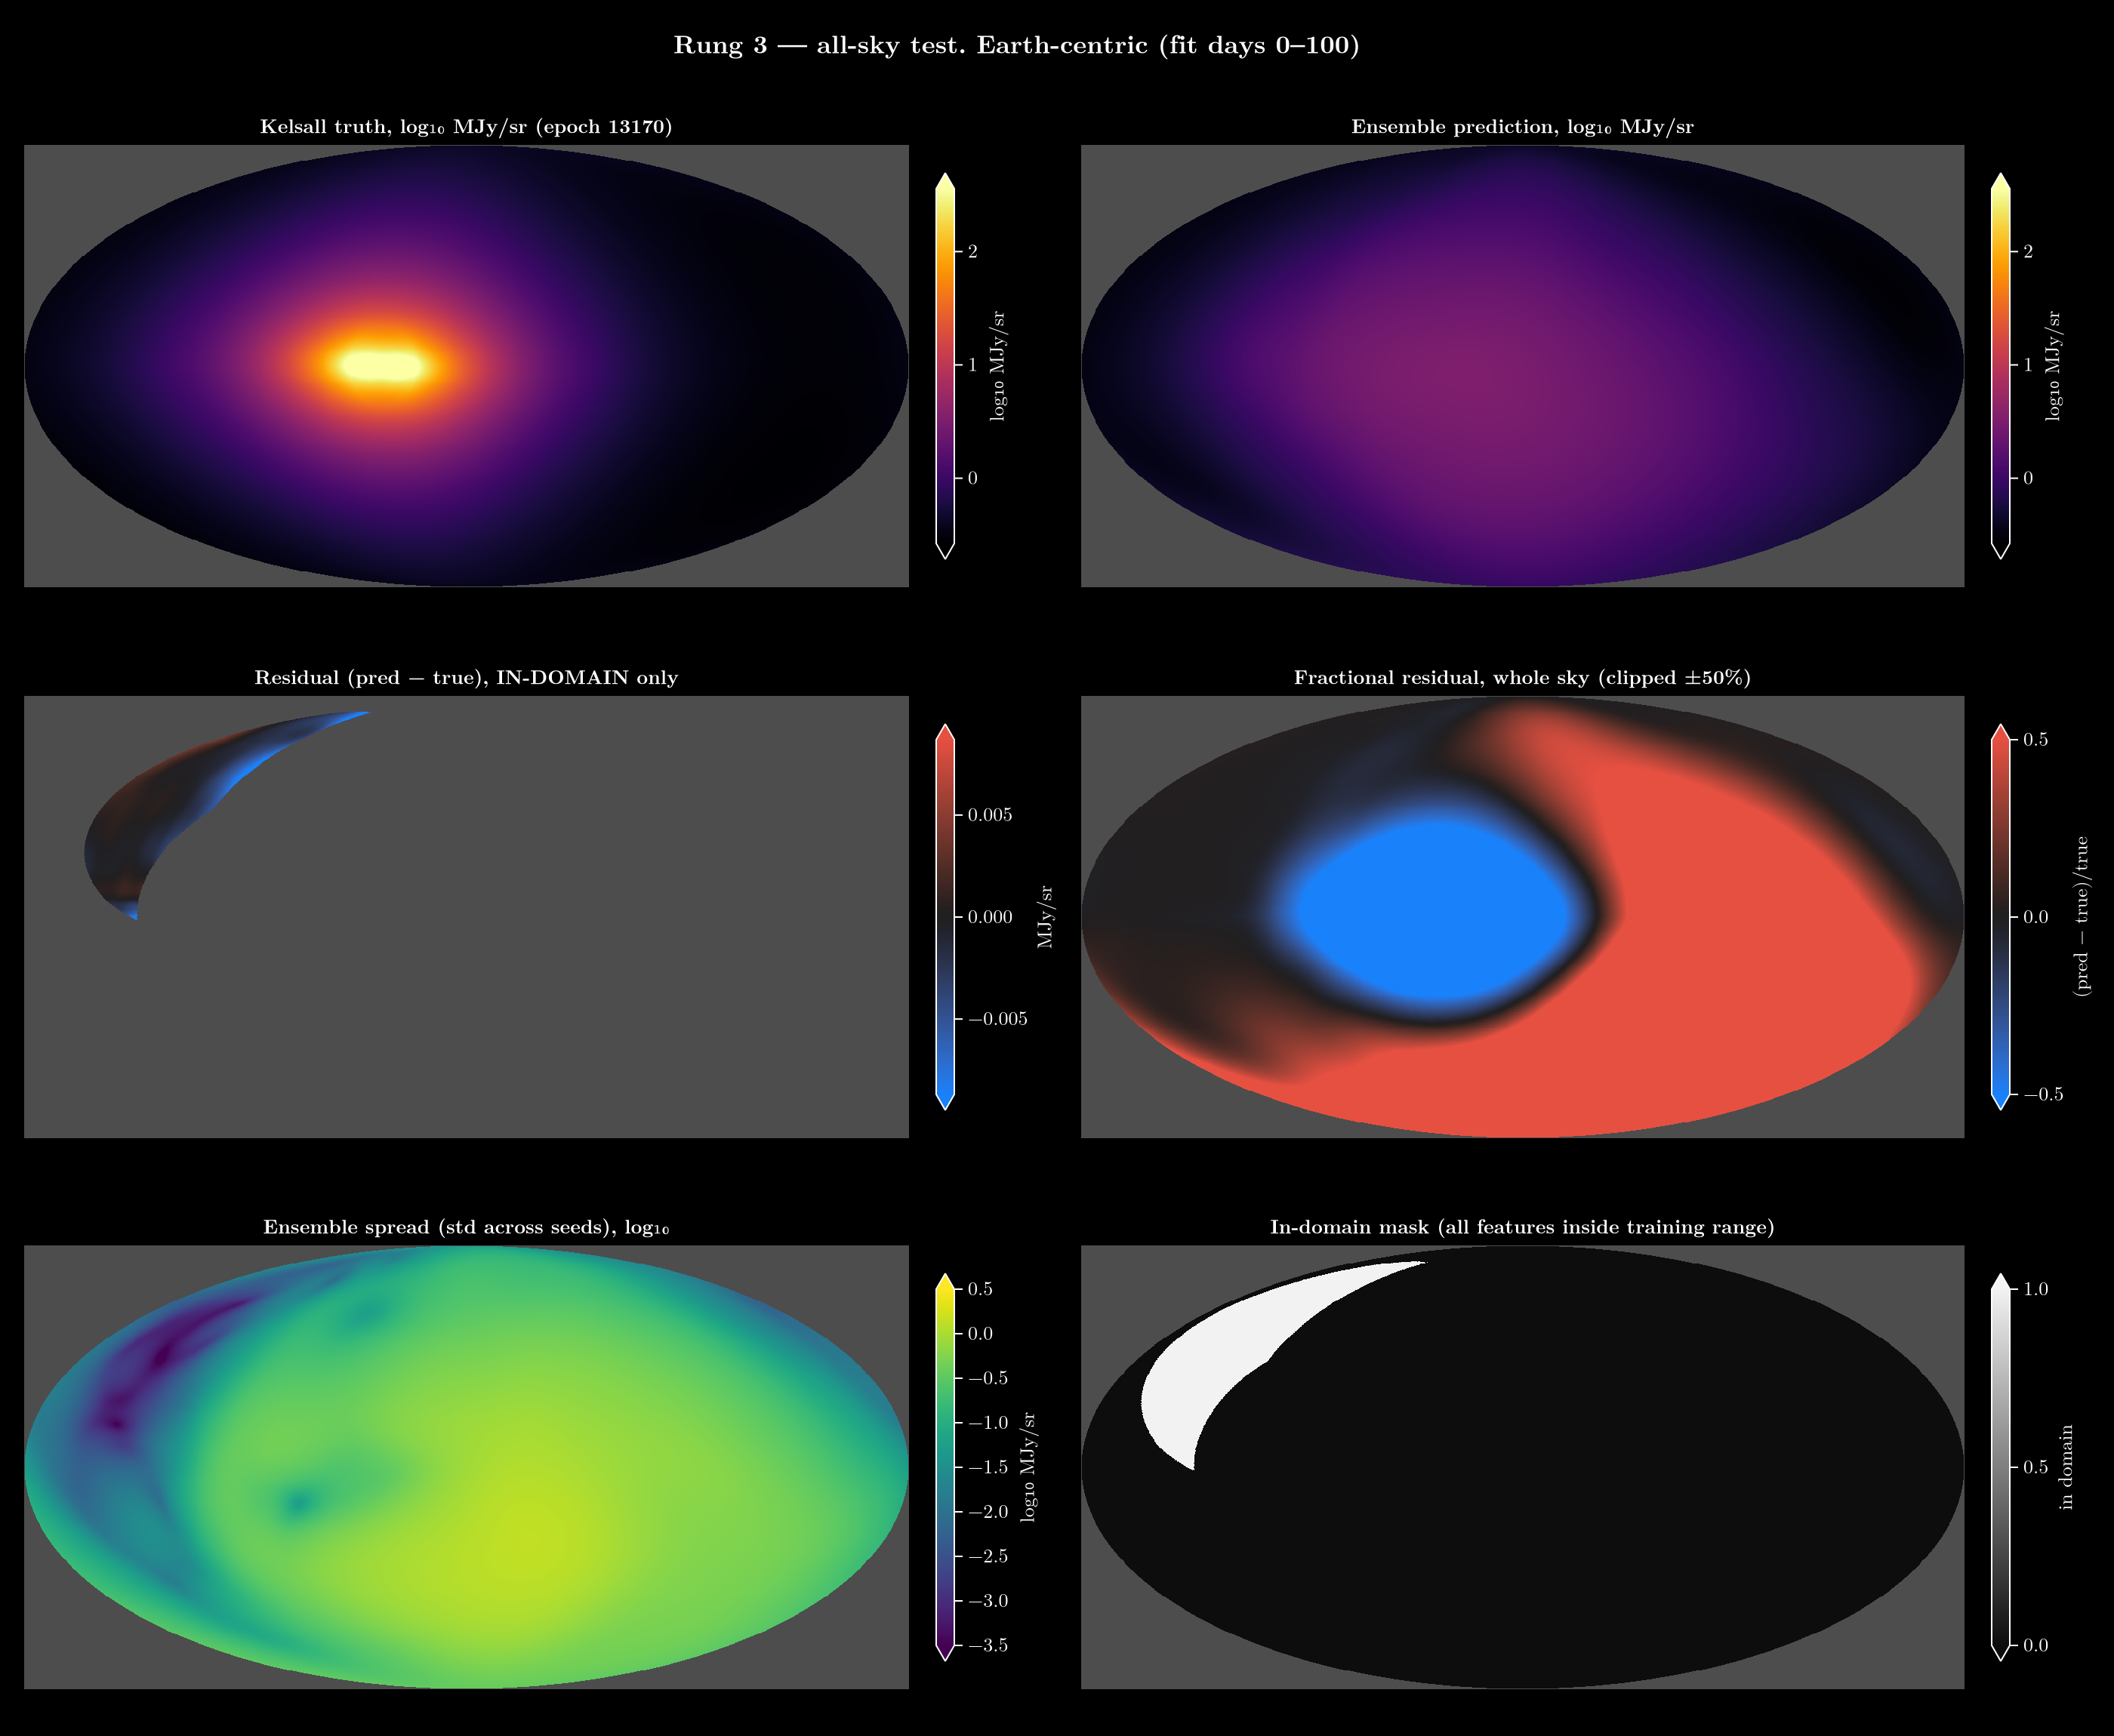

In [6]:
A_base = allsky_eval(load_prefix("v_base_s"); title="baseline (fit days 0–100)")
A_ec   = allsky_eval(ec_chrono; title="Earth-centric (fit days 0–100)")
display(vcat(insertcols!(copy(A_base.metrics), 1, :model => "baseline"), insertcols!(copy(A_ec.metrics), 1, :model => "Earth-centric")))
A_ec.fig


## B. A clean Jupiter null

### B1. Pre-flight: what each Jupiter-like feature contains
`moving_part_pct` = how much of the feature is NOT a fixed-sky-axis combination (n·x, n·y, n·z); `time_drift_R2` =
how much of that moving part is a smooth function of time (a clock). The 180° fake planet is shown only to confirm
it is just −n·J (an in-plane vector rotated 180° about the pole is its negative), which is why 90° was used instead.


In [7]:
jupiter_feature_table()


Row,feature,corr_with_nJ,moving_part_pct,time_drift_R2,test_out_of_train_range_pct
,String,Float64,Float64,Float64,Float64
1,n·J,1.0,3.4,0.601,27.0
2,n·Jrot45,0.4492,3.3,0.64,0.0
3,n·Jrot90,-0.2632,4.2,0.76,0.0
4,n·Jrot180,-1.0,3.4,0.6,27.0
5,n·Jscr,0.9958,7.4,0.0,17.3


### B2. Jupiter vs time-matched controls (chronological and interpolation splits)


In [8]:
display(compare_table(B_CHRONO))
display(compare_table(B_BLOCK))


Row,variant,seeds,val_ens,test_seed_median,test_seed_range,test_ens,test_ens_median_frac_pct,late_test_bias
,String,Int64,String,String,String,String,Float64,String
1,n·J (Jupiter),5,3.09e-05,4.46e-04,3.28e-04 – 5.59e-04,2.67e-04,1.438,-0.0144
2,"n·Jrot45 (fake planet, same motion)",5,1.98e-05,7.51e-04,2.95e-04 – 2.64e-03,4.09e-04,1.627,-0.0177
3,"n·Jrot90 (fake planet, same motion)",5,1.96e-05,1.30e-03,6.84e-04 – 3.27e-03,2.06e-04,1.269,-0.0077
4,"n·Jscr (Jupiter, time-scrambled)",5,2.34e-05,6.21e-04,2.25e-04 – 7.36e-03,5.22e-04,2.592,-0.0212
5,no Jupiter feature,5,2.97e-05,1.64e-03,3.17e-04 – 2.20e-03,6.76e-04,2.605,-0.0194


Row,variant,seeds,val_ens,test_seed_median,test_seed_range,test_ens,test_ens_median_frac_pct,late_test_bias
,String,Int64,String,String,String,String,Float64,String
1,n·J (Jupiter),3,—,1.36e-05,1.27e-05 – 1.57e-05,1.05e-05,0.167,—
2,"n·Jrot45 (fake planet, same motion)",3,—,1.76e-05,1.30e-05 – 1.91e-05,1.02e-05,0.171,—
3,"n·Jrot90 (fake planet, same motion)",3,—,1.30e-05,1.26e-05 – 3.38e-05,1.40e-05,0.156,—
4,"n·Jscr (Jupiter, time-scrambled)",3,—,1.99e-05,1.26e-05 – 2.34e-05,1.19e-05,0.14,—
5,no Jupiter feature,3,—,1.32e-05,1.06e-05 – 4.19e-05,9.86e-06,0.128,—


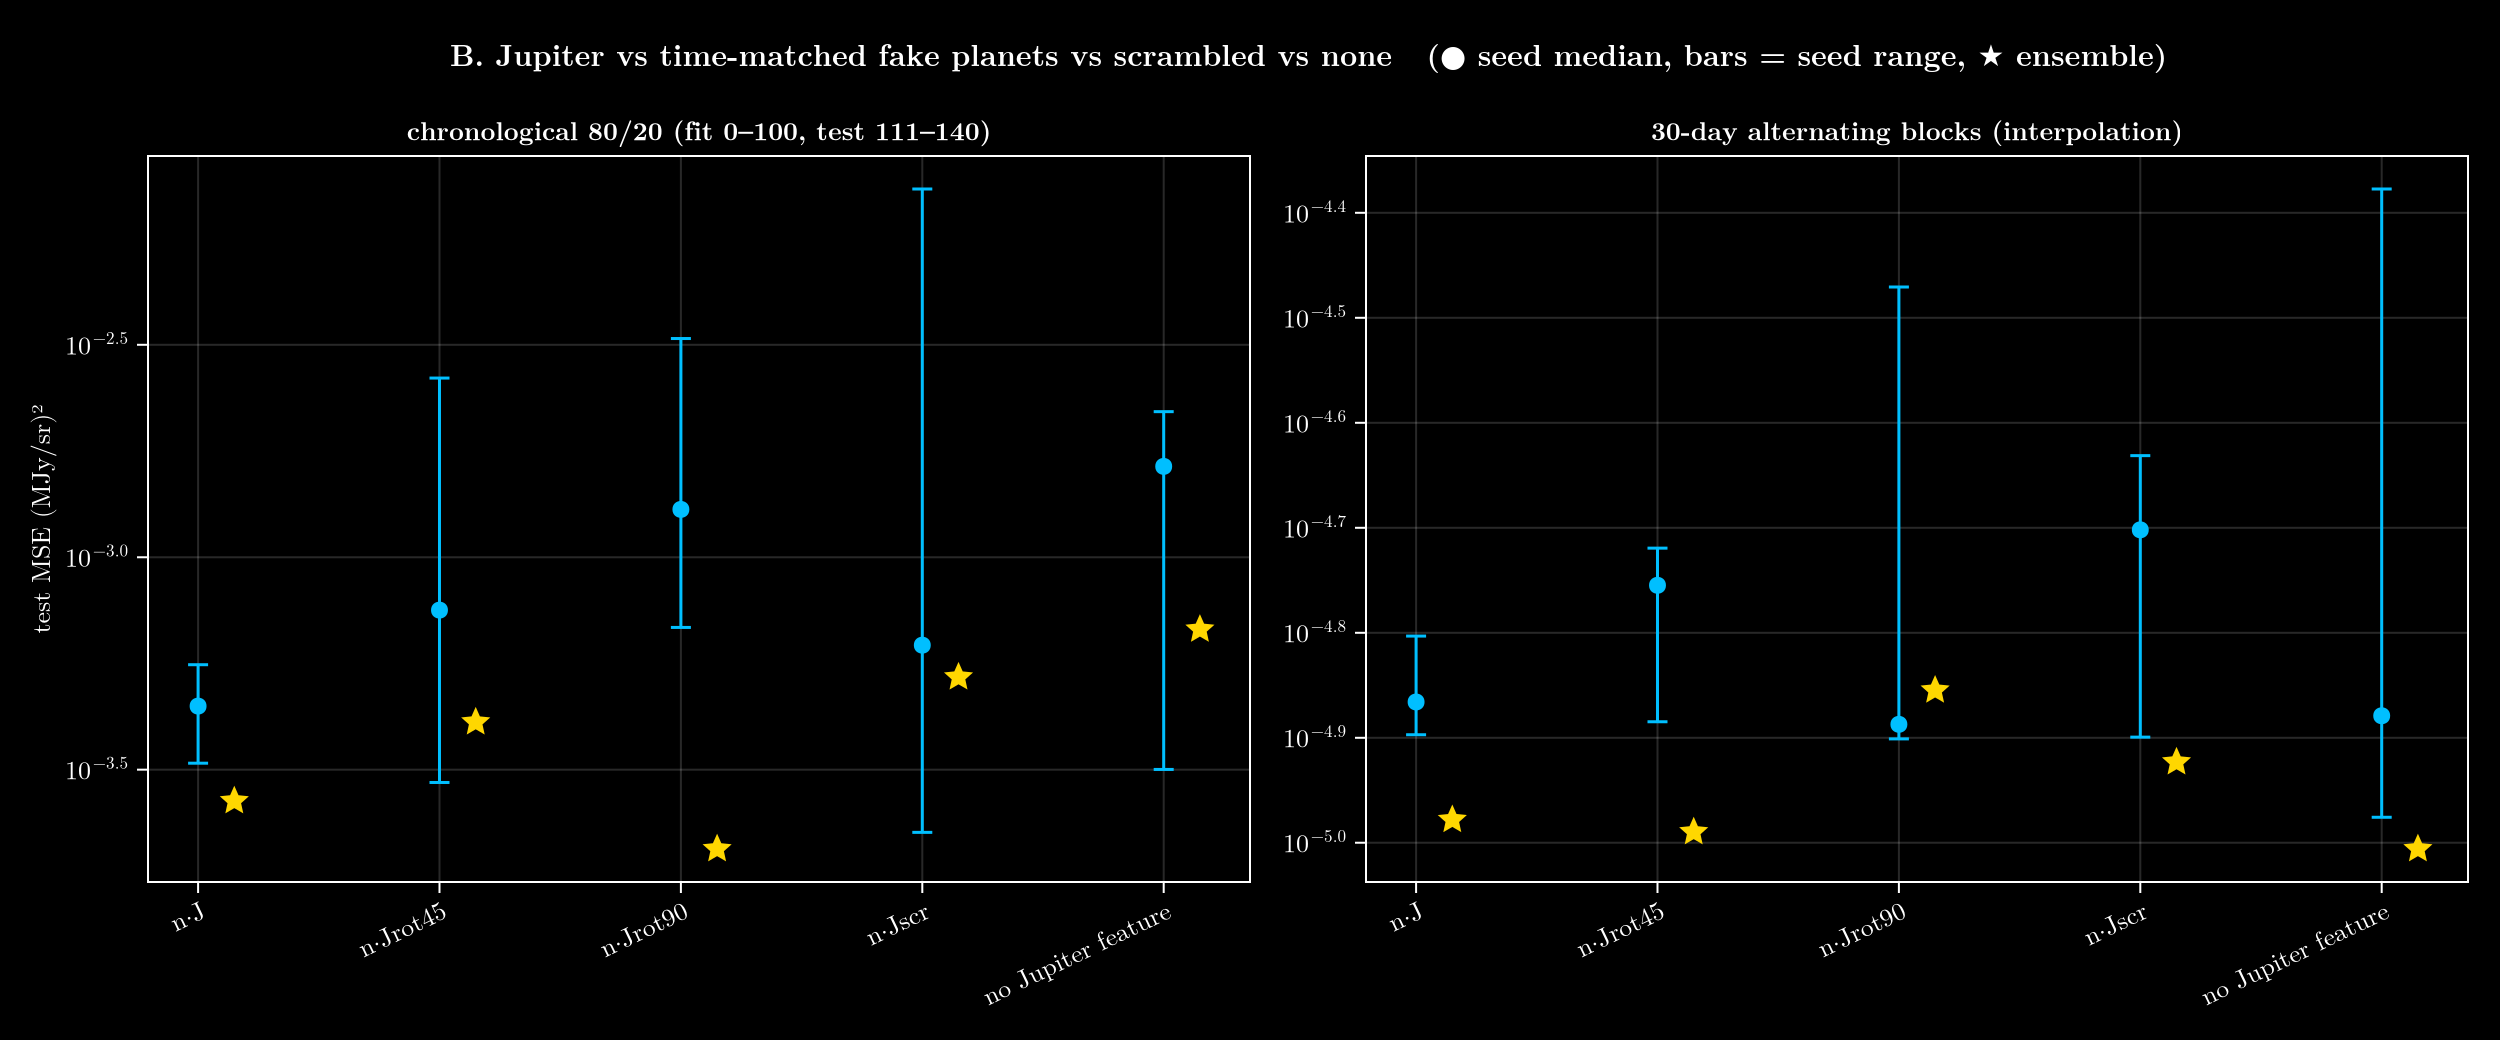

In [9]:
compare_fig(B_CHRONO, B_BLOCK; title="B. Jupiter vs time-matched fake planets vs scrambled vs none")


**Reading the figure.** Test **MSE** is dominated by a few seeds with large errors: the seed ranges overlap almost completely,
so MSE alone cannot rank these variants (an early impression that the 90° fake planet was worse came from single bad
seeds). Two more robust read-outs of the 5-seed ensembles — the **median fractional error** and the **bias in the last
10 days** — separate the variants cleanly by whether the feature carries **time information**:


In [10]:
chr = compare_table(B_CHRONO); blk = compare_table(B_BLOCK)
has_time = ["yes (Jupiter's motion)", "yes (same motion)", "yes (same motion)", "no (scrambled)", "no (absent)"]
DataFrame(variant=chr.variant, time_information=has_time,
          chrono_median_frac_err_pct=chr.test_ens_median_frac_pct, chrono_late_bias=chr.late_test_bias,
          block_median_frac_err_pct=blk.test_ens_median_frac_pct)


Row,variant,time_information,chrono_median_frac_err_pct,chrono_late_bias,block_median_frac_err_pct
,String,String,Float64,String,Float64
1,n·J (Jupiter),yes (Jupiter's motion),1.438,-0.0144,0.167
2,"n·Jrot45 (fake planet, same motion)",yes (same motion),1.627,-0.0177,0.171
3,"n·Jrot90 (fake planet, same motion)",yes (same motion),1.269,-0.0077,0.156
4,"n·Jscr (Jupiter, time-scrambled)",no (scrambled),2.592,-0.0212,0.14
5,no Jupiter feature,no (absent),2.605,-0.0194,0.128


### B4. Could it be Jupiter's dust (Trojan clouds leading/trailing Jupiter, Jupiter-family comet debris)?
Not in this experiment: the training target is the Kelsall (1998) model, whose components are listed below — none is tied
to Jupiter. And physically, dust at Jupiter's distance is very faint at 5 μm:


In [11]:
println("Kelsall components in the all-sky truth file: ",
        join(filter(k -> startswith(k, "emission_"), h5open(keys, allsky_file)), ", "))
# blackbody grain temperature T ≈ 278 K / √(r/AU); thermal emission at 5 μm ∝ 1/(exp(hc/λkT) − 1)
planck(λμm, T) = 1 / (exp(14388 / (λμm * T)) - 1)
T1, T5 = 278.0, 278.0 / sqrt(5.2)
@printf("grain temperature: %.0f K at 1 AU, %.0f K at 5.2 AU (peak emission near %.0f μm)\n", T1, T5, 2898 / T5)
@printf("5 μm thermal emission per grain at 5.2 AU relative to 1 AU: %.1e\n", planck(5, T5) / planck(5, T1))
@printf("scattered sunlight per grain falls as 1/r²: %.3f of the 1-AU value\n", 1 / 5.2^2)
println("→ at 5 μm, Jupiter-associated dust is many orders of magnitude fainter in thermal emission than the local cloud;\n" *
        "  if it is detectable at all it will be in scattered light at SPHEREx's shorter wavelengths — a real-data question.")


Kelsall components in the all-sky truth file: emission_circum_solar_ring, emission_dust_band_1, emission_dust_band_2, emission_dust_band_3, emission_earth_trailing_feature, emission_smooth_cloud
grain temperature: 278 K at 1 AU, 122 K at 5.2 AU (peak emission near 24 μm)
5 μm thermal emission per grain at 5.2 AU relative to 1 AU: 1.8e-06
scattered sunlight per grain falls as 1/r²: 0.037 of the 1-AU value
→ at 5 μm, Jupiter-associated dust is many orders of magnitude fainter in thermal emission than the local cloud;
  if it is detectable at all it will be in scattered light at SPHEREx's shorter wavelengths — a real-data question.


### B3. How much does each model lean on its Jupiter-like feature? — permutation importance (chronological test)


In [12]:
for (lbl, spec) in B_CHRONO[1:4]
    rs = grp_runs(spec); jf = filter(nm -> occursin("J", nm), rs[1].feature_names)[1]
    imp = perm_importance(rs, rs[1].te_idx)
    @printf("%-40s shuffle %-9s → MSE × %.3f   (most important feature: %s × %.2f)\n",
            lbl, jf, imp.mse_ratio_when_shuffled[findfirst(==(jf), imp.feature)], imp.feature[1], imp.mse_ratio_when_shuffled[1])
end


n·J  (Jupiter)                           shuffle n·J       → MSE × 110731.905   (most important feature: n·y × 128618.93)
n·Jrot45  (fake planet, same motion)     shuffle n·Jrot45  → MSE × 34.801   (most important feature: n·y × 97.57)
n·Jrot90  (fake planet, same motion)     shuffle n·Jrot90  → MSE × 8.523   (most important feature: n·vE × 70.95)
n·Jscr  (Jupiter, time-scrambled)        shuffle n·Jscr    → MSE × 5.041   (most important feature: n·z × 35.08)


## Conclusions

**A. Earth-centric control — a validated null, with one caveat.**
* Same accuracy in every test (chronological, interpolation, linear, linear+quadratic). The linear fits are *identical*
  because `{n·S, n·E}` and `{n·δ, n·E}` span the same space (`n·δ = n·S − n·E`).
* The coefficient check shows *why* the reparametrization is still worth it: in the barycentric set `n·S` and `n·E`
  get huge cancelling coefficients (+1110 / −1110 MJy/sr per σ) — the onboarding's near-duplicate warning — while
  the Earth-centric set is well conditioned (`n·δ` = 0.013, `n·E` = −0.03).
* `n·δ`'s linear coefficient (0.013 per σ) is ~6000× larger than real parallax could produce (~2×10⁻⁶ per σ), and
  shuffling it raises the network's error ×1.1 (chrono) / ×3.8 (block, from a tiny baseline): the network uses `n·δ` as a
  *redundant proxy* for pointing geometry (in SPHEREx's orbit the direction to Earth is tied to the Sun direction),
  not for parallax. Removing that proxy costs nothing in accuracy (identical ensemble MSE).
* Because |δ| is constant, `n·δ` ≈ |δ|·`n·δ̂` encodes the Earth-avoidance rule, so the all-sky in-domain region
  collapses from 32% to 5%. For an all-sky **emulator**, keep the barycentric `n·*` set. For **real data**, where you
  only predict at directions SPHEREx actually observed, Earth-anchored features (`n·δ̂`, Moon) are fine and needed
  for Earthshine/stray light.

**B. Jupiter null — the benefit is time information, not Jupiter.**
* The only thing `n·J` adds beyond the fixed sky axes is Jupiter's 12° motion (3–4% of the feature, R² ≈ 0.6 as a
  smooth function of time). Fake planets with the same motion carry the same kind of clock; scrambling removes it
  (R² = 0.000).
* Ensembles **with** time information (Jupiter, 45°, 90° fake planets): median error 1.27–1.63%, late bias −0.008 to −0.018.
  **Without** (scrambled, none): 2.59–2.61%, −0.019 to −0.021. On the interpolation split the differences shrink to
  ≤0.04 percentage points, and if anything the time-free variants are slightly better (0.13–0.14% vs 0.16–0.17%) —
  a clock only helps when extrapolating. Exactly the time-information pattern; a Jupiter-dust effect would instead
  make *real* Jupiter beat the fake planets on both splits.
* Kelsall contains no Jupiter-related component, and dust at 5.2 AU (~120 K) is ~10⁻⁶× fainter per grain in 5 μm
  thermal emission than dust at 1 AU — so even on real 5 μm data a Jupiter-dust signal would be tiny.
* Permutation importance is **not** a reliable diagnostic here: `n·J` (corr 0.999 with `n·y`) looks "essential" only
  because it duplicates the `n·y` geometry.

**What this means going forward**
1. Treat any feature that drifts with time (planets, Earth's orbital position, `S·S`) as a *clock* first, physics second.
   A Jupiter test on real data needs time-matched controls (fake planets) — "with vs. without Jupiter" is not a null.
2. Better: give the model explicit, periodic season features (e.g. Earth's ecliptic longitude as sin/cos) and train on
   a full year, so time enters as physics instead of leaking in through incidental features.
3. Rank models by robust metrics (median error, bias, ensembles), not by single-seed MSE.
